Our goal is to teach a computer to read text and predict which category that text belongs to.


For example:

    "NASA launched a new satellite" → Space / Science

    "The football team won the match" → Sports

    "Python is a programming language" → Computers

In [25]:
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [26]:
categories = [
    "comp.graphics",
    "sci.space",
    "rec.sport.baseball",
    "talk.politics.misc"
]

data = fetch_20newsgroups(
    subset="all",
    categories=categories,
    remove=("headers", "footers", "quotes")
)

X = data.data
y = data.target

print("Total documents:", len(X))
print("Categories:", data.target_names)
print("First document:", X[0][:500])

Total documents: 3729
Categories: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']
First document: 
Are you kidding?  I'm stuck with the Toronto SkyDome, where their idea
of a 7th inning stretch is that "Blue Jays" song where everyone gets
to yell:  "Okay, okay, Blue Jays, Blue Jays, Let's Play Ball!"

Wow.. what genius did it take to compose that one, to outshine the
old classic.  And there are women on the field to "lead the crowd".


In [27]:
#  Check the number of documents in each category
unique, counts = np.unique(y, return_counts=True)

for category_id, count in zip(unique, counts):
    print(data.target_names[category_id], count)

comp.graphics 973
rec.sport.baseball 994
sci.space 987
talk.politics.misc 775


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2983
Testing samples: 746


In [29]:
# Step 4 — Convert text into numerical features

vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (2983, 10000)
Testing matrix: (746, 10000)


In [30]:
# Step 5 — Train Logistic Regression
model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [31]:
# Step 6 — Make predictions

predictions = model.predict(X_test_tfidf)

print(predictions[:10])
print(y_test[:10])

[1 3 2 1 3 3 1 2 1 2]
[1 3 2 1 3 3 1 2 3 2]


In [32]:
accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", accuracy)

print(
    classification_report(
        y_test,
        predictions,
        target_names=data.target_names
    )
)


Accuracy: 0.8887399463806971
                    precision    recall  f1-score   support

     comp.graphics       0.94      0.95      0.95       195
rec.sport.baseball       0.91      0.83      0.87       199
         sci.space       0.80      0.93      0.86       197
talk.politics.misc       0.94      0.84      0.89       155

          accuracy                           0.89       746
         macro avg       0.90      0.89      0.89       746
      weighted avg       0.89      0.89      0.89       746



In [33]:
# Step 8 — Inspect the confusion matrix

cm = confusion_matrix(
    y_test,
    predictions
)

print(cm)

[[185   3   5   2]
 [  2 165  27   5]
 [  7   6 183   1]
 [  2   8  15 130]]


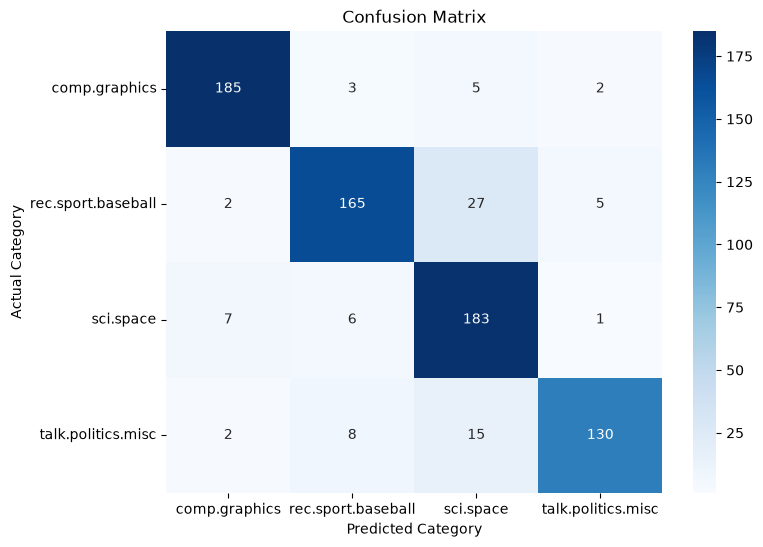

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix")

plt.show()

In [35]:
import numpy as np

# Find documents where prediction is incorrect
wrong_indices = np.where(y_test != predictions)[0]

print("Total incorrect predictions:", len(wrong_indices))

# Inspect the first 5 incorrect predictions
for i in wrong_indices[:5]:

    print("\nActual category:",
          data.target_names[y_test[i]])

    print("Predicted category:",
          data.target_names[predictions[i]])

    print("Document:")
    print(X_test[i][:500])

    print("-" * 80)

Total incorrect predictions: 83

Actual category: talk.politics.misc
Predicted category: rec.sport.baseball
Document:

But remember that had God extinguished the blasphemous trash of Europe (and
Imperialism with it), the United States would not exist today to put an end
to those "games"....begs the question, which came first, the chicken or the
egg???
--------------------------------------------------------------------------------

Actual category: rec.sport.baseball
Predicted category: sci.space
Document:

--------------------------------------------------------------------------------

Actual category: rec.sport.baseball
Predicted category: sci.space
Document:



--------------------------------------------------------------------------------

Actual category: talk.politics.misc
Predicted category: sci.space
Document:

	My understanding from my psycology classes is that the percentage is 
	more like 10-12% world wide.  I would really like to know your source
	for the 1-2% figure.
---

In [36]:
# Select one incorrectly classified document
i = wrong_indices[0]

# Get probability scores for each category
probabilities = model.predict_proba(
    X_test_tfidf[i]
)[0]

# Print the document
print("Document:")
print(X_test[i][:500])

# Print actual category
print("\nActual:")
print(data.target_names[y_test[i]])

# Print predicted category
print("\nPredicted:")
print(data.target_names[predictions[i]])

# Print probabilities
print("\nCategory probabilities:")

for category, probability in zip(
    data.target_names,
    probabilities
):
    print(category, round(probability * 100, 2), "%")

Document:

But remember that had God extinguished the blasphemous trash of Europe (and
Imperialism with it), the United States would not exist today to put an end
to those "games"....begs the question, which came first, the chicken or the
egg???

Actual:
talk.politics.misc

Predicted:
rec.sport.baseball

Category probabilities:
comp.graphics 11.07 %
rec.sport.baseball 41.7 %
sci.space 21.83 %
talk.politics.misc 25.4 %


In [37]:
# Experiment B — Compare algorithms : Train a second model

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print(
    "Naive Bayes Accuracy:",
    accuracy_score(y_test, nb_predictions)
)

print("Logistic Regression:",
      accuracy_score(y_test, predictions))

print("Naive Bayes:",
      accuracy_score(y_test, nb_predictions))

print("NAIVE BAYES REPORT")

print(classification_report(
    y_test,
    nb_predictions
))

Naive Bayes Accuracy: 0.9048257372654156
Logistic Regression: 0.8887399463806971
Naive Bayes: 0.9048257372654156
NAIVE BAYES REPORT
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       195
           1       0.83      0.96      0.89       199
           2       0.94      0.86      0.90       197
           3       0.95      0.82      0.88       155

    accuracy                           0.90       746
   macro avg       0.91      0.90      0.90       746
weighted avg       0.91      0.90      0.90       746



In [38]:
print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])

print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))
print("TF-IDF features:", X_train_tfidf.shape[1])

Training samples: 2983
Testing samples: 746
Training labels: 2983
Testing labels: 746
TF-IDF features: 10000


In [39]:
# Investigate the documents your Naive Bayes model classified incorrectly.
wrong_indices = np.where(
    nb_predictions != y_test
)[0]

print("Incorrect predictions:", len(wrong_indices))

for i in wrong_indices[:10]:

    print("\nActual:",
          data.target_names[y_test.iloc[i]]
          if hasattr(y_test, "iloc") else y_test[i])

    print("Predicted:",
          data.target_names[nb_predictions[i]])

Incorrect predictions: 71

Actual: 3
Predicted: rec.sport.baseball

Actual: 3
Predicted: sci.space

Actual: 2
Predicted: talk.politics.misc

Actual: 3
Predicted: sci.space

Actual: 3
Predicted: rec.sport.baseball

Actual: 2
Predicted: comp.graphics

Actual: 2
Predicted: comp.graphics

Actual: 2
Predicted: rec.sport.baseball

Actual: 0
Predicted: rec.sport.baseball

Actual: 3
Predicted: sci.space


In [40]:
# Experiment C — Custom predictions

custom_texts = [
    "NASA launched a spacecraft to explore Mars",
    "The baseball team won the championship",
    "New computer graphics technology is amazing",
    "The government announced a new political policy"
]

custom_tfidf = vectorizer.transform(custom_texts)

custom_predictions = model.predict(custom_tfidf)

for text, prediction in zip(
    custom_texts,
    custom_predictions
):
    print(
        "Text:", text, 
        "| Prediction:", data.target_names[prediction]
    )

Text: NASA launched a spacecraft to explore Mars | Prediction: sci.space
Text: The baseball team won the championship | Prediction: rec.sport.baseball
Text: New computer graphics technology is amazing | Prediction: comp.graphics
Text: The government announced a new political policy | Prediction: talk.politics.misc


In [41]:
# Step 1 — Create a pipeline
from sklearn.pipeline import Pipeline
import joblib

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",10000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [ ]:
joblib.dump(pipeline, "classifier.joblib")

In [ ]:
loaded_model = joblib.load("classifier.joblib")

text = ["NASA launched a rocket toward Mars"]

prediction = loaded_model.predict(text)

print(data.target_names[prediction[0]])

sci.space


In [ ]:
def predict_category(text):

    prediction = loaded_model.predict([text])

    category = data.target_names[prediction[0]]

    return category

In [ ]:
predict_category("NASA discovered a new planet")

# Expected output:
# sci.space

In [ ]:
predict_category("The baseball team won the championship")

predict_category("New computer graphics technology")

predict_category("The government announced a political policy")